# import libraries

In [ ]:
import pandas as pd

import tensorflow as tf
from tensorflow.keras import layers, Sequential
from tensorflow.keras.datasets import mnist
from tensorflow.keras.utils import to_categorical
from keras.callbacks import EarlyStopping
import matplotlib.pyplot as plt

import numpy as np

169001437/169001437 ━━━━━━━━━━━━━━━━━━━━ 3122s 18us/step


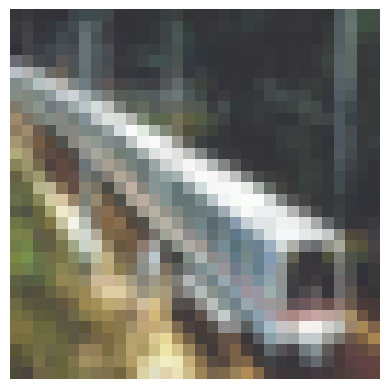

In [ ]:
# load dataset

(X_train,y_train),(X_test,y_test) = tf.keras.datasets.cifar100.load_data()

image = X_train[6]

# to display the image

plt.imshow(image,cmap="gray")
plt.axis('off')
plt.show()

In [ ]:
# shape

print(X_train.shape)

(50000, 32, 32, 3)


In [ ]:
# preprocess data

X_train = tf.expand_dims(X_train,-1)
X_test = tf.expand_dims(X_test,-1)

print(X_train.shape)

(50000, 32, 32, 3, 1)


In [ ]:
# normalize pixel vales -[0-255] to []

X_train = tf.cast(X_train,tf.float32) / 255.0
X_test = tf.cast(X_test,tf.float32) / 255.0

In [ ]:
# one hot encoding the target ,becausenmodel should no feel like larger number has higher piority
y_train = to_categorical(y_train, 100)
y_test = to_categorical(y_test, 100)

In [ ]:
# define the model (streamlined for memory efficiency)
vgg_11_model = Sequential([
    # resize only the current batch
    layers.Resizing(224, 224, input_shape=(32, 32, 3)),
    # block 1: 224 * 224 -> 112*112
    layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D((2, 2), strides=(2, 2)),
    # Block 2: 112*112 -> 56*56
    layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D((2, 2), strides=(2, 2)),
    # block 3 : 56*56 -> 28*28
    layers.Conv2D(256, (3, 3), activation='relu', padding='same'),
    layers.Conv2D(256, (3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D((2, 2), strides=(2, 2)),
    # block 4 : 28*28 -> 14*14
    layers.Conv2D(512, (3, 3), activation='relu', padding='same'),
    layers.Conv2D(512, (3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D((2, 2), strides=(2, 2)),
    # block 5 : 14*14 -> 7*7
    layers.Conv2D(512, (3, 3), activation='relu', padding='same'),
    layers.Conv2D(512, (3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D((2, 2), strides=(2, 2)),
    # classifiers head
    layers.Flatten(),
    layers.Dense(512, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(100, activation='softmax'),
])

In [ ]:
# compile model

vgg_11_model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics = ['accuracy']
)

In [ ]:
# to view the model

vgg_11_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resizing_2 (Resizing)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_16 (Conv2D)              │ (None, 224, 224, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_17 (Conv2D)              │ (None, 112, 112, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_18 (Conv2D)              │ (None, 56, 56, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_19 (Conv2D)              │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_12 (MaxPooling2D) │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_20 (Conv2D)              │ (None, 28, 28, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_21 (Conv2D)              │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_13 (MaxPooling2D) │ (None, 14, 14, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_22 (Conv2D)              │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_23 (Conv2D)              │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_14 (MaxPooling2D) │ (None, 7, 7, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 512)            │    12,845,568 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 100)            │        51,300 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 22,117,348 (84.37 MB)

 Trainable params: 22,117,348 (84.37 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
earlystopping=EarlyStopping(
    monitor="val_loss",
    min_delta=0,
    patience=0,
    verbose=0,
    mode="auto",
    baseline=None,
    restore_best_weights=False,
    start_from_epoch=0,
)


NameError: name 'EarlyStopping' is not defined

In [ ]:
# to train

vgg_11_model.fit(X_train,y_train,batch_size=64,epochs=100,validation_split=0.1,callbacks=[earlystopping])

Epoch 1/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 305s 433ms/step - accuracy: 0.0092 - loss: 4.6056 - val_accuracy: 0.0078 - val_loss: 4.6072
Epoch 2/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 310s 440ms/step - accuracy: 0.0092 - loss: 4.6056 - val_accuracy: 0.0070 - val_loss: 4.6074
Epoch 3/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 310s 440ms/step - accuracy: 0.0095 - loss: 4.6056 - val_accuracy: 0.0070 - val_loss: 4.6075
Epoch 4/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 310s 440ms/step - accuracy: 0.0084 - loss: 4.6056 - val_accuracy: 0.0074 - val_loss: 4.6076
Epoch 5/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 310s 440ms/step - accuracy: 0.0093 - loss: 4.6056 - val_accuracy: 0.0074 - val_loss: 4.6076
Epoch 6/100
605/704 ━━━━━━━━━━━━━━━━━━━━ 42s 425ms/step - accuracy: 0.0086 - loss: 4.6053

KeyboardInterrupt: 

In [ ]:
# evalute

test_less ,test_acc=vgg_11_model.evaluate(X_test,y_test)

print("Test accuracy ",test_acc)

313/313 ━━━━━━━━━━━━━━━━━━━━ 29s 80ms/step - accuracy: 0.0100 - loss: 4.6052
Test accuracy  0.009999999776482582


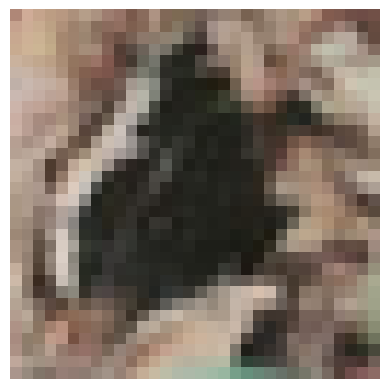

In [ ]:
# select row and remove the trailing singleton dimension for plotting
sample_tensor = tf.squeeze(X_test[7])
plt.imshow(sample_tensor)
plt.axis('off')
plt.show()

In [ ]:
# add batch dimension to row sample for model input:
input_tensor =np.expand_dims(sample_tensor,axis=0)

# predict using the explicit CNN model
predictions =vgg_11_model.predict(input_tensor)

#get predicted class
predicted_class = np.argmax(predictions[0])


print(f"\n Predicted Digits : {predicted_class}")
print(f"Class probabliites : {predictions[0].round(3)}")

1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step

 Predicted Digits : 32
Class probabliites : [0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01
 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01
 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01
 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01
 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01
 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01
 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01
 0.01 0.01]
